In [56]:
%load_ext autoreload
%autoreload 2

import os
import sys
import numpy as np
import pandas as pd

sys.path.append('./src')
import tl_field_selector as fs
import tl_cat_creator as tlc
import visualisation as vs
import optimize_fields as opt
import tl_guide_fibre_allocator as gfa


from astropy.io import fits
from astropy.table import Table

from tl_protofielding import create_twilight_input_catalogue, TLOBXML, TLDriverCat, create_plate_fits_file, assign_targprog

# Import after the previous packages to enable correct plotting
%matplotlib inline
import matplotlib.pyplot as plt

# Warnings regarding stage6 can be safely ignored at the time of writing. 

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# DEFINING WTL FIELDS

 ## Before you start:
 
**DISCLAIMER: This mode is currently under development and may produce unexpected results!** </br> </br>

**IMPORTANT** </br>
**1. To run this notebook correctly your IP has to be whitelisted on WASP!** (wasp.ast.cam.ac.uk) </br>

**2. If you do not have a WASP validated FITS file yet, you can use a different target identifier in your fits file (src_id_col).** </br>
**However, the FITS file must have been created in a WASP-compliant format. This means that all its mandatory columns, except CNAME, have to be filled!**

**3. It is important that you run the OB creation for every field plate separately!** </br> </br>


**General Info:** </br>
**"WTL"** stands for **"WEAVE Tumble-Less"**, and refers to the fact that it enables observations of multiple fields without the need to tumble the field plates. This means that you can **observe up to 3 fields (pointings) with a single fibre configuration**. A **collection of fields** that are observed with the same fibre configuration is referred to as a **"field batch"**. </br>
This observing mode obviously places strict limits on the number of targets that can be observed for each of the individual field. </br>
It is therefore necessary that you define your input catalogues accordingly. </br> </br>
**This means that the target density per 2 square degrees (WEAVE FOV) should not exceed 300, as there are only ~900 fibres on each plate!** </br>
The routine below is **optimised to maximize the number of fields per batch, prioritizing batches with 3 fields**. </br>
The on-sky offset between individual fields has been succesfully tested to up to 15 deg. However the real **limit is set by atmospheric differential refraction**. </br>
For good measure we recommend **offsets between fields should not be larger than 5 deg!** </br>
If you have **offsets between target groups** in your input catalogue that are **larger than 5 deg** you should consider **splitting your input catalogue** into different regions that have coherent coordinate coverage. </br> 
This can be done easily by **modfying the pandas.DataFrame** after reading in the fits catalogue. Then the notebook can be **run for each of the dataframes**.


## Open the WASP FITS file and extract its contents as a pandas.DataFrame

In [26]:
fits_cat_path = "./WS2025XX-XXX.fits"
targsrvy = os.path.splitext(os.path.basename(fits_cat_path))[0]
src_id_col = 'CNAME'
print(targsrvy)


WS2025XX-XXX


In [27]:
with fits.open(fits_cat_path) as hdu:
    cat_df = Table(hdu[1].data).to_pandas()

print(cat_df.shape)


(911, 227)


In [58]:
print(cat_df.head(3))
cat_df.head(50).

                  CNAME      TARGSRVY             TARGPROG            TARGCAT  \
0  WVE_16123540+5647429  WS2022A2-002  WS2022A2-002|GALAXY  WS2022A2-002.fits   
1  WVE_16124278+5647234  WS2022A2-002  WS2022A2-002|GALAXY  WS2022A2-002.fits   
2  WVE_16125681+5647003  WS2022A2-002  WS2022A2-002|GALAXY  WS2022A2-002.fits   

              TARGID  TARGNAME  TARGPRIO TARGUSE TARGCLASS PROGTEMP  ...  \
0  76557899425424437  ELAIS-N1       1.0       T   UNKNOWN    11331  ...   
1  76557899425424053  ELAIS-N1       1.0       T   UNKNOWN    11331  ...   
2  76557899425423801  ELAIS-N1       1.0       T   UNKNOWN    11331  ...   

  WISE_MAG_W1 WISE_MAG_W1_ERR WISE_MAG_W2  WISE_MAG_W2_ERR  WISE_MAG_W3  \
0   19.288280           0.047   19.958813            0.133    18.376610   
1   18.013220           0.029   18.465771            0.047    16.567596   
2   17.912077           0.028   17.974670            0.036    16.104565   

   WISE_MAG_W3_ERR  WISE_MAG_W4  WISE_MAG_W4_ERR     WISE_RA  healpix

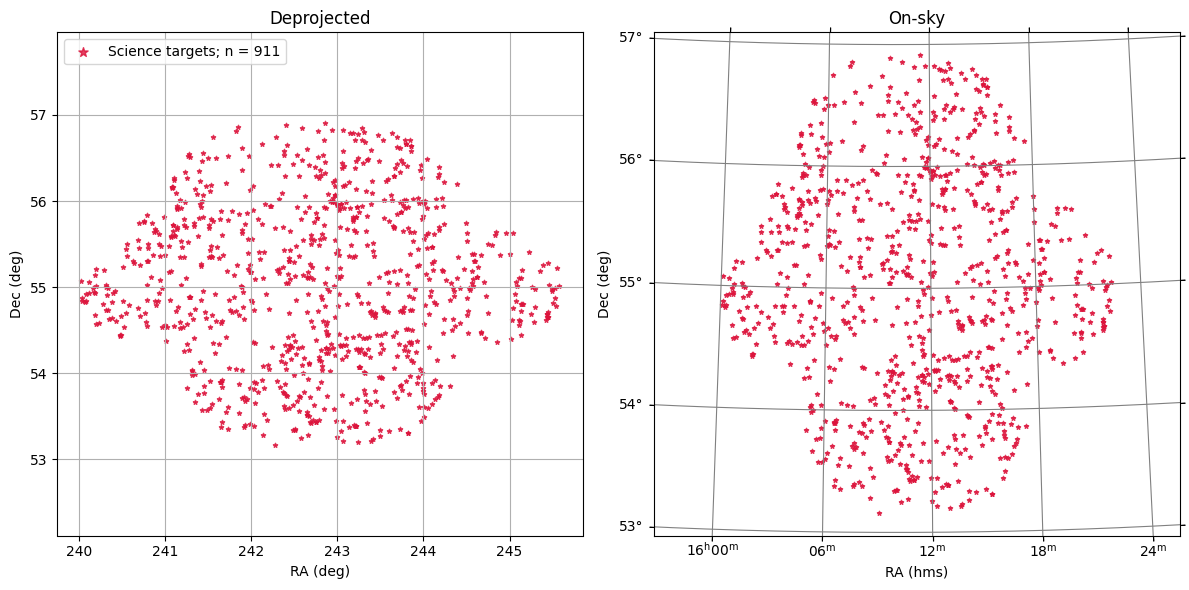

In [28]:
vs.plot_input_fits_cat(cat_df, center=(242.5, 53))

## Add a Healpix ID column to enable WEAVE Guide Catalogue (WG) query

In [63]:
cat_df = tlc.add_healpix_id(cat_df, ra_col='GAIA_RA', de_col='GAIA_DEC',
                            hp_col='healpixId', nside=32, nested=True)

# Get the healpix ids for querying the WEAVE guide star catalogue
healpix_ids = cat_df['healpixId'].unique()
print(healpix_ids)

[2881 2880 2539 2537 2538 2536]


## Query WEAVE Guide Catalogue (This can take time, depending on the how many healpix ids you are querying)!

In [64]:
tlc.query_weave_guide_stars(healpix_ids=healpix_ids,
                        split_nr=None,
                        mag_low=14.5,
                        mag_high=15,
                        cache=False,
                        neighbour_hp=True)

## Read-in the created WG parquet file

In [65]:
wg_df = pd.read_parquet('./resources/WG/WG_all.parquet')
cat_comb_df = tlc.combine_wg_with_input_cat(cat_df, wg_df, src_id_col=src_id_col)
#print(cat_comb_df.sample(10))

## Define the on-sky fields
**Returns a dataframe cotaining all targets that are assigned to fields and guide stars.** </br>
The second dataframe returned is a lookup table tracking field assignments. This is used as input for the guide fibre allocation.

In [66]:
test_circles = pd.DataFrame({'GAIA_RA':[241.5, 244.1, 242.8, 242.73],
                             'GAIA_DEC':[55.0, 55.1, 55.9, 53.75]})

Using provided circles dataframe for field definition.
----------------------------------------------
Total placed circles: 4
----------------------------------------------
Field defnition completed!
Nr. of targets: 
Science: 909
Guide: 4
----------------------------------------------
Batch ID assignment completed!
Nr. of field batches: 2
----------------------------------------------


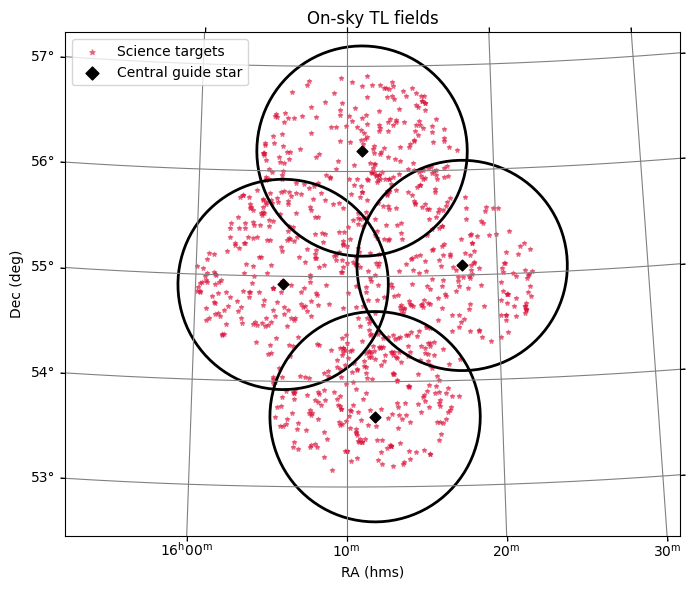

In [68]:
pd.set_option('display.max_rows', None)
field_stars, lut_df = fs.define_fields(cat_comb_df, grid_offset=0.61, #0.61,     #0.61, # 1.65, 1.615
                                        central_star_mag_lim=16.,
                                        src_id_col=src_id_col,
                                        verbose=True,
                                        fixed_grid=False,
                                        circles_df=test_circles,
                                        prune_fields=True)


vs.plot_tl_fov_coverage(field_stars_df=field_stars, center=(242.5, 53),
                     coords='radec', figsize=(7, 6))



## Experimental:
We want to optimize the search for a good grid_offset parameter. This parameter defines the offsets in degree on the sky of a uniformly spaced grid of 2 deg circles (FOV) on the sky. In define_fields() it is used as an intial configuration in the optimization of best field coverage, using a minimal amount of circles. The cell below runs the function with different grid_offset values over a given range. The default range runs from 0.3 to 1.3 in steps of 0.01. If the default option is not satisfactory, you can provide your own offset range. 

In [39]:
best_grid_offset = opt.sweep_offsets(cat_comb_df,
                                fs,
                                offsets=np.round(np.arange(0.6, 1.2 + 1e-9, 0.01), 3), # supply custom offset range here
                                central_star_mag_lim=16.,
                                src_id_col=src_id_col,
                                fixed_grid=True,
                                prune_fields=True)

print("Best grid_offset:", best_grid_offset["offset"])
print("Metrics:", best_grid_offset["metrics"])

Best grid_offset: 0.68
Metrics: {'n_science': 911, 'n_fields': 5, 'coverage_frac': 1.0}


## Create a dictionary containing the fibre ids of guide fibres NOT in operation, for both field plates

In [14]:
fibre_file_path = './resources/fibresINGGenerated_20250716.xml'

# To check for avaiable guide fibres set fibre_ids_to_check=None!
broken_fibres = gfa.check_guide_fibre_status(fibre_status_xml=fibre_file_path, fibre_ids_to_check=None)
print(broken_fibres)

{'A': [879], 'B': [249]}


## Allocate suitable guide fibres for each merged field configuration. </br> **This has to be done for each plate and hemisphere (+ or - Dec).**
Disabled or broken guide fibres are taken into account.

In [31]:
import warnings
warnings.filterwarnings("ignore")

plate='A' # Set plate accordingly
hemisphere='N' # Set to S for catalogues where all targets have Dec < 0

coverage = gfa.run_guide_fibre_allocation(field_stars,
                                          cat_comb_df,
                                          lut_df,
                                          hemisphere=hemisphere,
                                          plate=plate,
                                          guide_mag_limit=16.0,
                                          verbose=True,
                                          src_id_col=src_id_col,
                                          broken_fibres=broken_fibres,
                                          add_sky_targets=True,
                                          max_num_sky_targets=15,
                                          outpath='./')



Allocation in progress for plate A - N
------------------------------------------------------------------------
Batch ID:  1
Guide fibre assignment: 
------------------------------------------------------------------------
                  CNAME  fieldId  guide  fibreId  sourceFlag  GAIA_MAG_G
6  WVE_16054761+5455193      1.0    1.0    123.0           9   14.611074
1  WVE_16055681+5400562      1.0    2.0   1005.0           9   14.598782
4  WVE_16090721+5521135      1.0    2.0    375.0           9   14.716498
7  WVE_16110291+5611395      2.0    1.0    123.0           9   14.994586
0  WVE_16063623+5617397      2.0    2.0    753.0           9   14.505270
2  WVE_16102827+5658347      2.0    2.0    501.0           9   14.657169
8  WVE_16114936+5340039      3.0    1.0    123.0           9   14.665492
3  WVE_16080607+5411384      3.0    2.0    627.0           9   14.680164
5  WVE_16172706+5335206      3.0    2.0    249.0           9   14.832232
-----------------------------------------------

# OB-XML CREATION

## Define necessary parameters for the PHU of the plate-FITS files. The plate-FITS files are only used to create the TL-OB-xmls and should NOT be uploaded to WASP! 

In [16]:
print(f'./temp_outputs/{targsrvy}_{plate}_{hemisphere}.fits')


./temp_outputs/WS2025XX-XXX_A_N.fits


In [17]:
progtemp, obstemp = create_plate_fits_file(infile=fits_cat_path,
                                           coverage_df=coverage, plate=plate,
                                           hemisphere=hemisphere,
                                           src_id_col=src_id_col,
                                           outpath=f'./')

# Check if your PROGTEMP and OBSTEMP are correct!
print("PROGTEMP:", progtemp)
print("OBSTEMP: ", obstemp)


PROGTEMP: 11331
OBSTEMP:  EAAEB


## Create TL-Driver catalogue object. This enables the creation of TL-OB-xmls. 

In [18]:
tl_driver = TLDriverCat(filename=f'./WS2025XX-XXX_{plate}_{hemisphere}.fits',
                        guide_star_csv=f'./guide_stars_{plate}_{hemisphere}.csv',
                        expcal_json='./resources/expcal.json')



## Also we define the individual field batches by extracting the unique batch ids from the guide stars CSV created when running create_plate_fits_file().

In [19]:
target_csv_path = f'./central_target_list_{plate}_{hemisphere}.csv'
central_target_df = pd.read_csv(target_csv_path)
print(central_target_df.shape[0], 'central guide stars found!')
field_batch_ids = central_target_df['batchId'].unique()

5 central guide stars found!


## Create the TL-CONFIGURE ready OB xmls
Adding calibration stars (calib_stars=True) ONLY works for targets with CNAMEs (created from a sWASP validated FITS file)!!! </br>
When adding calibration stars you might see some Warnings regarding "missing keys in the target attribute lookup". </br> You can safely ignore them.

In [32]:
for batch_id in field_batch_ids:
    #try:
    tl_driver.process_tl_ob(batch_id, target_csv_path,
                              h_suffix=hemisphere,
                              progtemp= '11331', #progtemp,
                              obstemp='EAAEB', # obstemp,
                              plate=f'PLATE_{plate}',
                              calib_stars=False,
                              output_dir=f'./xmls/plate_{plate}/{hemisphere}/',
                              guide_mag_lim=16.,
                              calib_mag_lim=20,#17.9,
                              min_guide_cut=0.1,
                              max_guide_cut=0.98,
                              suffix=batch_id,
                              verbose=False,
                              ob_class='science',
                              field_name='DEMO'
                      )
    #except:
     #   print(f'An error occurred')
      #  print(f'Skipping batch {batch_id}, continuing with next batch...')
       # continue
print('-------------------- DONE --------------------')

-----------------------------------------------------------------------
Processing TL OB batch-ID: 1.0; field plate: PLATE_A; pa: 180
-----------------------------------------------------------------------


-----------------------------------------------------------------------
Processing TL OB batch-ID: 2.0; field plate: PLATE_A; pa: 180
-----------------------------------------------------------------------
-------------------- DONE --------------------


## Set the epoch for TL-CONFIGURE

Jan 1st: 2025.000 <br>
Feb 1st: 2025.083 <br>
Mar 1st: 2025.166 <br>
Apr 1st: 2025.250 <br>
May 1st: 2025.333 <br>
Jun 1st: 2025.416 <br>
Jul 1st: 2025.500 <br>
Aug 1st: 2025.583 <br>
Sep 1st: 2025.666 <br>
Oct 1st: 2025.750 <br>
Nov 1st: 2025.833 <br>
Dec 1st: 2025.916 <br>


epoch = year + (month-1)/12

In [651]:
epoch=2025.750

## Run TL-CONFIGURE. The most recent fibre status XML should be supplied in --fibre_status!!! We already defined its path above, so we use fibre_file_path again. 

In [652]:
! ./configure_tl/bash_scripts/./run_tl_configure.sh --epoch {epoch} --plate {plate} --hemisphere {hemisphere} --fibre_status {fibre_file_path}

Running twilight_configure --fibre_status with: ./resources/fibresINGGenerated_20250716.xml
Processing ./xmls/plate_A/N/WS2025XX-XXX_pA_DEMO_01_b001_N.xml -> ./xmls/configure_A/WS2025XX-XXX_pA_DEMO_01_b001_N_2025.75_conf.xml
Processing ./xmls/plate_A/N/WS2025XX-XXX_pA_DEMO_01_b002_N.xml -> ./xmls/configure_A/WS2025XX-XXX_pA_DEMO_01_b002_N_2025.75_conf.xml


## Define paths for final TL-CONFIGURE output

In [399]:
configure_output_path = f'./xmls/configure_{plate}/'
print('Finalization input path:', configure_output_path)
final_configure_output_path = f'./xmls/configure_{plate}/finalized_{plate}/' #{trimester}/'
print('Finalization output path:', final_configure_output_path)

Finalization input path: ./xmls/configure_A/
Finalization output path: ./xmls/configure_A/finalized_A/


## Set how many exposures per field we want.

In [400]:
num_science_exp = 3
science_exptime = 1020

## Finalize the OB-xmls so they will be read correctly by the Observatory Control System (OCS). This step is essential, as the TL-OB-XML structure differs significantly from regular MOS OBs!!!

In [401]:
from xml.parsers.expat import ExpatError

for xml in os.listdir(configure_output_path):
    if xml.endswith('.xml'):
        xml_path = os.path.join(configure_output_path, xml)
        try:
            tl_driver.finalize_tl_ob(xml_path, output_dir=final_configure_output_path,
                                   progtemp=progtemp,
                                   num_science_exposures=num_science_exp,
                                   science_exptime=science_exptime, 
                                   field_name='WTLS',
                                   xml_verbosity=True,
                                   drop_targinfo_from_field=True,
                                   # casuid_minus_1=False
                                   )

        # Checking for blank xmls due to a field position angle outside the rotator limits
        except ExpatError as e:
            print(f"Skipping {xml} due to XML parsing error: {e}")
            continue
        except SystemExit as e:
            print(f"Skipping {xml} due to SystemExit: {e} \n"
                  "Likely caused due to field position angle being outside the positioner limits, \n"
                  "resulting in an empty configure output xml.")
            continue 
        except AttributeError as e:
            print(f"Skipping {xml} due to AttributeError: {e}.")
            continue


## The final OB-XMLs can now be uploaded to WASP for validation. They can be found in the finalized_* folder inside the xmls/configure_* directory.


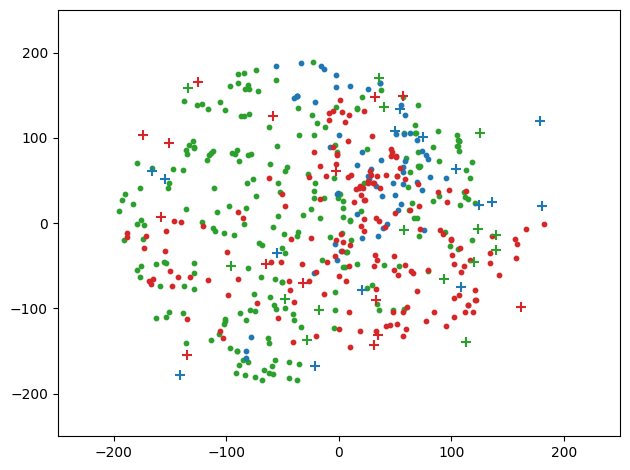

In [52]:
field_id = 4

science_0 = coverage[(coverage['sourceFlag'] == 0) & (coverage['fieldId'] == 1)]
science_1 = coverage[(coverage['sourceFlag'] == 0) & (coverage['fieldId'] == 2)]
science = coverage[(coverage['sourceFlag'] == 0) & (coverage['fieldId'] == field_id)]

sky_1 = coverage[(coverage['sourceFlag'] == -1) & (coverage['fieldId'] == 1)]
sky_0 = coverage[(coverage['sourceFlag'] == -1) & (coverage['fieldId'] == 2)]
sky = coverage[(coverage['sourceFlag'] == -1) & (coverage['fieldId'] == field_id)]

plt.scatter(science['X'], science['Y'], s=10, color='tab:green')
plt.scatter(science_0['X'], science_0['Y'], s=10, color='tab:blue')
plt.scatter(science_1['X'], science_1['Y'], s=10, color='tab:red')

plt.scatter(sky['X'], sky['Y'], s=50, color='tab:green', marker='+')
plt.scatter(sky_0['X'], sky_0['Y'], s=50, color='tab:blue', marker='+')
plt.scatter(sky_1['X'], sky_1['Y'], s=50, color='tab:red', marker='+')


plt.xlim(-250, 250)
plt.ylim(-250, 250)
#plt.axis('equal')
plt.tight_layout()
plt.show()